In [3]:
#1)Load the dataset

import pandas as pd
import numpy as np
df = pd.read_csv('/content/train_loan.csv')
df



,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [4]:
#2)Check dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [5]:
#3)Describe the dataset
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [6]:
#4)Check duplicate values
df.duplicated().sum()

np.int64(0)

In [7]:
#5)Check missing values
df.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [16]:
#6)Handling missing values

#Fill categorical columns with mode
cat_cols = [
    'Gender',
    'Married',
    'Dependents',
    'Self_Employed',
    'Credit_History'
]
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Fill numerical columns with median
num_cols = ['LoanAmount', 'Loan_Amount_Term']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

df.isnull().sum()

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


In [9]:
#7)display all column headings
df.columns


Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

ApplicantIncome


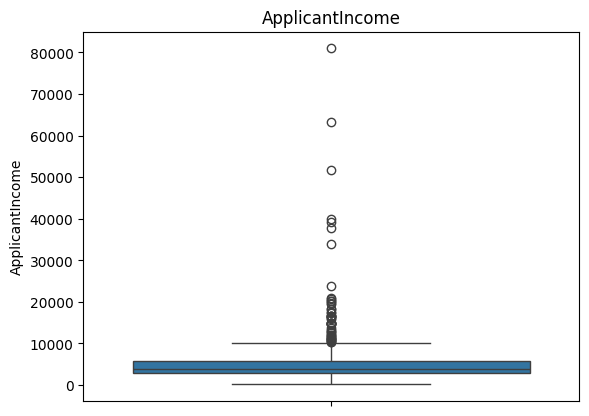

CoapplicantIncome


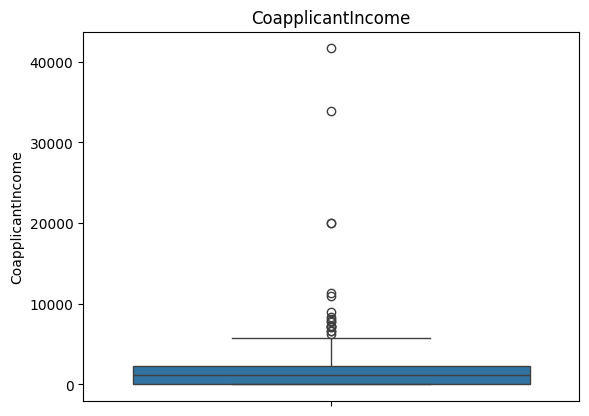

LoanAmount


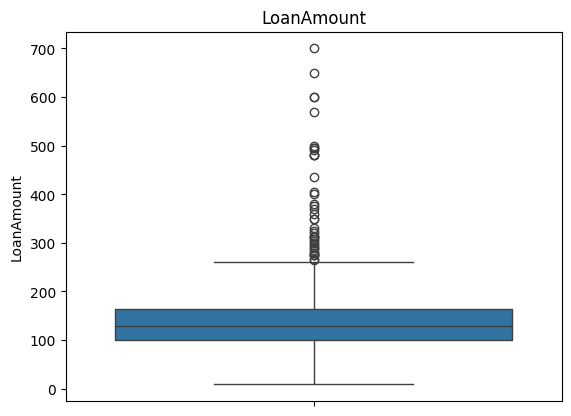

Loan_Amount_Term


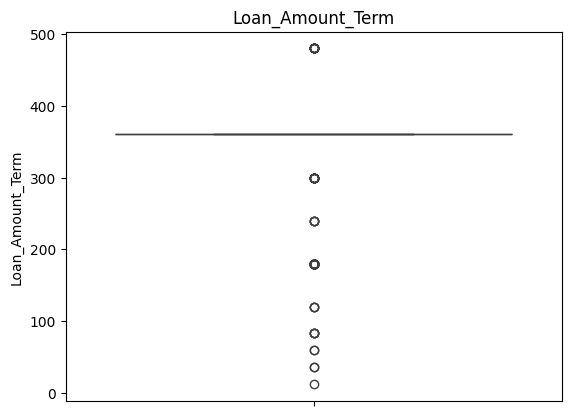

Credit_History


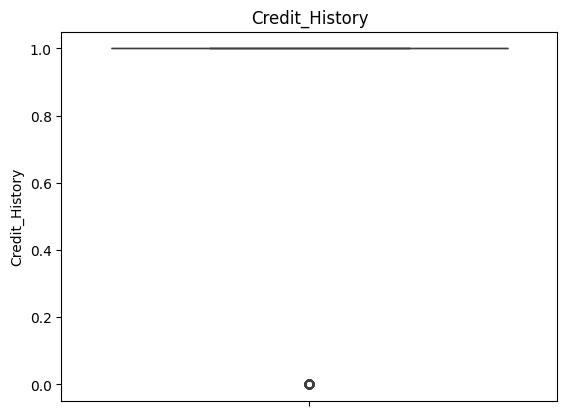

In [10]:
#8)outlier detection using boxplots
import matplotlib.pyplot as plt
import seaborn as sns
for i in df.select_dtypes("number").columns:
  print(i)
  sns.boxplot(df[i])
  plt.title(i)
  plt.show()

In [19]:
#9)skewness of all numerical columns
df.select_dtypes("number").skew().sort_values(ascending=False) #desc

,0
CoapplicantIncome,7.491531
ApplicantIncome,6.539513
LoanAmount,2.743053
Credit_History,-2.021971
Loan_Amount_Term,-2.402112


In [20]:
#10)remove outliers from numerical columns using the IQR (Interquartile Range) method
import pandas as pd

def remove_outliers(df, columns):
    df_filtered = df  # Make a copy of the original DataFrame

    for i in columns:
        Q1 = df[i].quantile(0.25)#Calculate Q1 and Q3
        Q3 = df[i].quantile(0.75)
        IQR = Q3 - Q1 #Calculate IQR

        lower_whisker = Q1 - 1.5 * IQR #Calculate the lower and upper limits
        upper_whisker = Q3 + 1.5 * IQR

        # Filter out rows where column values are outliers
        df_filtered = df_filtered[(df_filtered[i] >= lower_whisker) & (df_filtered[i] <= upper_whisker)]

    return df_filtered
dff=remove_outliers(df,["CoapplicantIncome","ApplicantIncome","LoanAmount","Credit_History","Loan_Amount_Term"])


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
607,LP002964,Male,Yes,2,Not Graduate,No,3987,1411.0,157.0,360.0,1.0,Rural,Y
608,LP002974,Male,Yes,0,Graduate,No,3232,1950.0,108.0,360.0,1.0,Rural,Y
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y


In [21]:
#11)One-Hot Encoding
import pandas as pd
# Select categorical columns
cat_cols = [
    'Gender',
    'Married',
    'Education',
    'Self_Employed',
    'Property_Area',
     'Loan_Status'
]

# Apply One-Hot Encoding
df2 = pd.get_dummies(dff, columns=cat_cols, drop_first=True, dtype=int)
df2


,Loan_ID,Dependents,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Male,Married_Yes,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban,Loan_Status_Y
0,LP001002,0,5849,0.0,128.0,360.0,1.0,1,0,0,0,0,1,1
1,LP001003,1,4583,1508.0,128.0,360.0,1.0,1,1,0,0,0,0,0
2,LP001005,0,3000,0.0,66.0,360.0,1.0,1,1,0,1,0,1,1
3,LP001006,0,2583,2358.0,120.0,360.0,1.0,1,1,1,0,0,1,1
4,LP001008,0,6000,0.0,141.0,360.0,1.0,1,0,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
607,LP002964,2,3987,1411.0,157.0,360.0,1.0,1,1,1,0,0,0,1
608,LP002974,0,3232,1950.0,108.0,360.0,1.0,1,1,0,0,0,0,1
609,LP002978,0,2900,0.0,71.0,360.0,1.0,0,0,0,0,0,0,1
611,LP002983,1,8072,240.0,253.0,360.0,1.0,1,1,0,0,0,1,1


In [22]:
#12)Standard Scaling
from sklearn.preprocessing import StandardScaler

# Select numerical columns
num_cols = [
    'ApplicantIncome',
    'CoapplicantIncome',
    'LoanAmount',
    'Loan_Amount_Term'
]

# Create scaler
scaler = StandardScaler()

# Apply scaling
df2[num_cols] = scaler.fit_transform(df2[num_cols])

# Display the result
df2[num_cols]

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
0,0.960029,-0.953550,-0.010551,0.0
1,0.280905,0.109487,-0.010551,0.0
2,-0.568268,-0.953550,-1.388519,0.0
3,-0.791960,0.708679,-0.188354,0.0
4,1.041031,-0.953550,0.278377,0.0
...,...,...,...,...
607,-0.038809,0.041108,0.633982,0.0
608,-0.443816,0.421066,-0.455057,0.0
609,-0.621911,-0.953550,-1.277393,0.0
611,2.152519,-0.784367,2.767610,0.0
